In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '3'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

In [4]:
x = np.random.uniform(1, 3, size=10000)
x_err = np.random.uniform(0.1, 0.5, size=10000) + x * 0.6
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

### Fit

In [35]:
from raddest.api.fitter import FlowVI

In [36]:
flow_vi = FlowVI(x_min=max(0, x_obs.min()),
                 x_max=x_obs.max(),
                 x_err_min=x_err.min() * 0.8,
                 x_err_max=x_err.max() * 1.2)

In [48]:
flow_vi.fit(x_obs,
            x_err,
            n_pre=1000,
            n_train=10_000,
            n_node=51,
            verbose=True,
            check_per_step=10,
            early_stop=True,
            max_stuck=5,
            stuck_frac=0.01,
            guess_method='auto',
            skip_fitting_if_init_good=False)

100%|██████████| 1000/1000 [00:33<00:00, 29.85it/s]


step 0: loss 8.890050888061523
step 10: loss 5.248245716094971
step 20: loss 2.8856630325317383
step 30: loss 2.107116460800171
step 40: loss 1.8622626066207886
step 50: loss 1.7782129049301147
step 60: loss 1.7246097326278687
step 70: loss 1.6853238344192505
step 80: loss 1.6614574193954468
step 90: loss 1.646751880645752
step 100: loss 1.635183572769165
step 110: loss 1.6263951063156128
step 120: loss 1.6193957328796387
step 130: loss 1.613732933998108
step 140: loss 1.6083168983459473


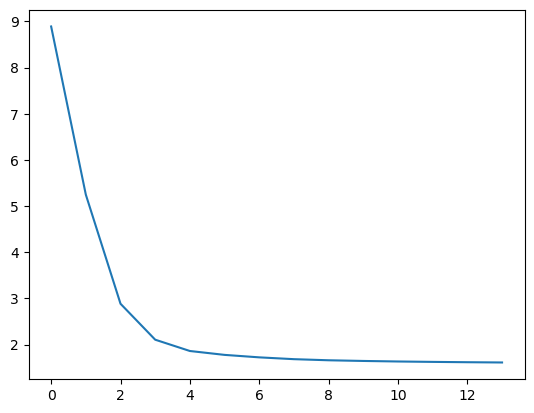

In [49]:
plt.plot(flow_vi.loss)

In [50]:
x_gen, x_err_gen, x_obs_gen = flow_vi.sample(10000, return_numpy=True)

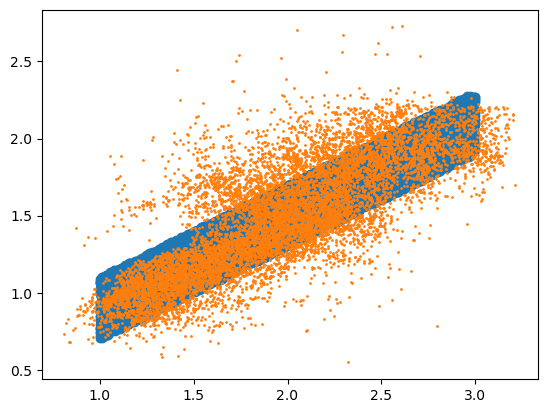

In [51]:
plt.scatter(x, x_err)
plt.scatter(x_gen, x_err_gen, s=1)

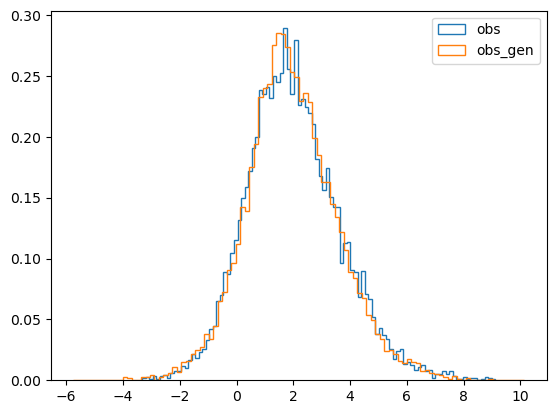

In [52]:
plt.hist(x_obs, bins=100, histtype='step', density=True, label='obs');
plt.hist(x_obs_gen, bins=100, histtype='step', density=True, label='obs_gen');
plt.legend()

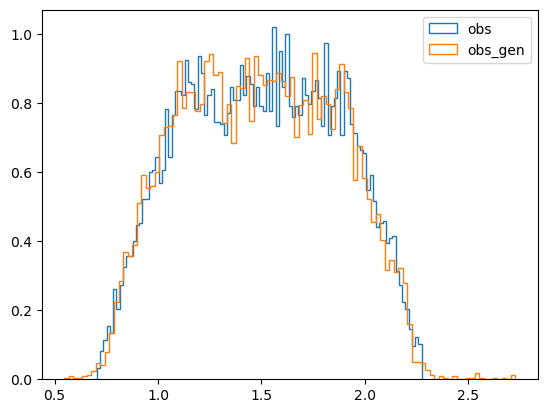

In [53]:
plt.hist(x_err, bins=100, histtype='step', density=True, label='obs');
plt.hist(x_err_gen, bins=100, histtype='step', density=True, label='obs_gen');
plt.legend()

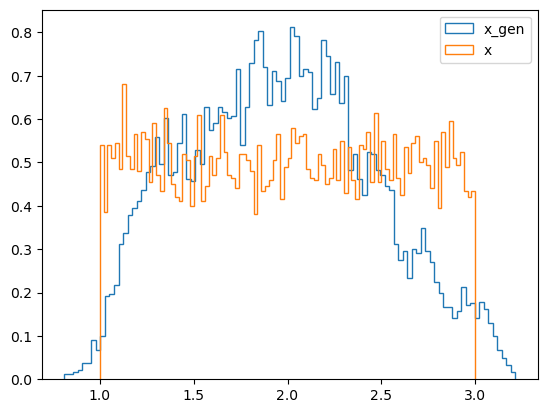

In [54]:
plt.hist(x_gen, bins=100, histtype='step', density=True, label='x_gen');
plt.hist(x, bins=100, histtype='step', density=True, label='x');
plt.legend()

In [55]:
flow_vi.ks_test(x_obs, x_err, 10000)

(0.0358000174164772, 0.0004095014236095436)

In [56]:
D_lst, p_lst = flow_vi.ks_test(x_obs, x_err, N=10000, K=100, M=10000)

In [57]:
10**np.mean(np.log10(p_lst))

9.431901706532011e-05

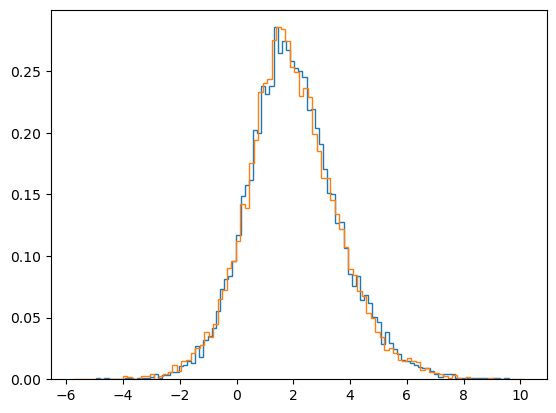

In [58]:
! rm -rf test

flow_vi.save('test')
flow_loaded = FlowVI.load('test')

x_gen_load, x_err_gen_load, x_obs_gen_load = flow_loaded.sample(10000, 0, x_obs.max(), 0, x_err.max() * 1.2, return_numpy=True)

plt.hist(x_obs_gen_load, bins=100, histtype='step', density=True, label='obs_gen_load');
plt.hist(x_obs_gen, bins=100, histtype='step', density=True, label='obs_gen');

# remove the folder
! rm -rf test

### Guess

We can heuristically "guess" the intrinsic value and then pre-train the NF model on this guessed value to get a good starting point for the optimization. This approach is automatically implemented in the `FlowVI.fit` method. 

Here we show an example of guessed x - x_err correlation.

In [6]:
from raddest.shrink import shrink_data

In [95]:
x = np.random.uniform(1, 3, size=10000)
x_err = np.random.uniform(0.1, 0.5, size=10000) + x * 0.6
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

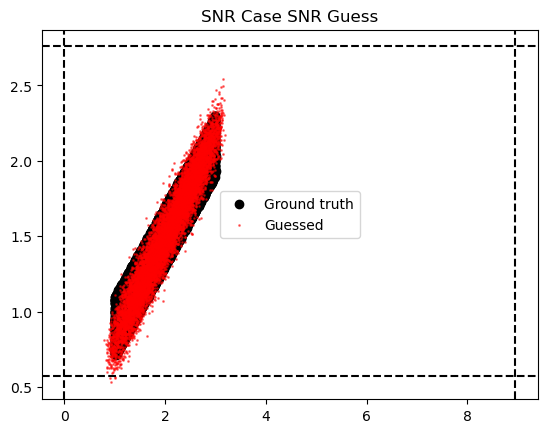

In [ ]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='SNR',
                                     to_recalibrate=False)
plt.title('SNR Case SNR Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')

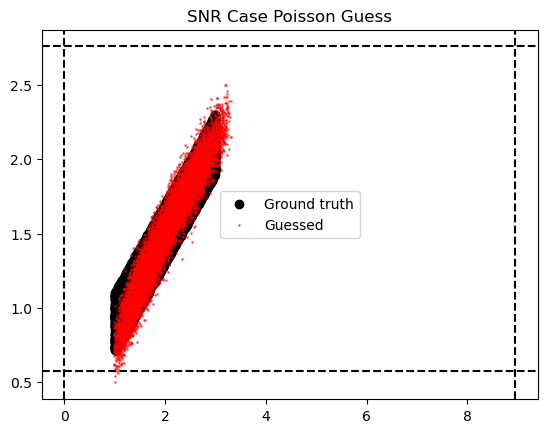

In [98]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='poisson',
                                     to_recalibrate=True)
plt.title('SNR Case Poisson Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')

In [100]:
x = np.random.uniform(1, 3, size=10000) # S_x ~ 0.576
x_err = np.random.uniform(0.1, 0.5, size=10000) + np.sqrt(x) * 0.6 # sigma ~ 0.115 
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

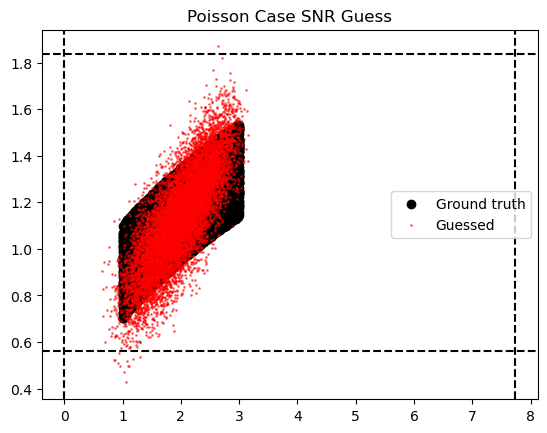

In [101]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='SNR',
                                     to_recalibrate=False)
plt.title('Poisson Case SNR Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')

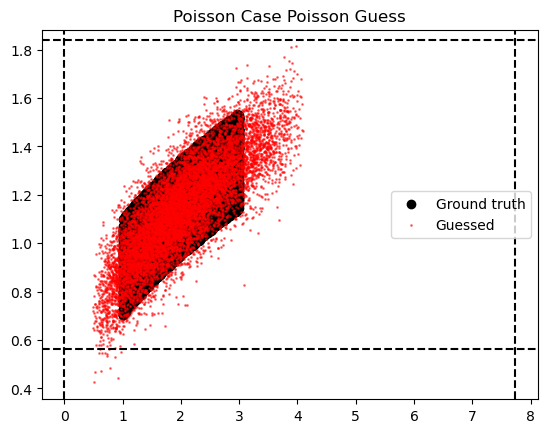

In [102]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='poisson',
                                     to_recalibrate=False)
plt.title('Poisson Case Poisson Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')